| $y(t), y[n]$ | Memoryless | Linear | Time-Invariant | Causal | Invertible | Stable |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **(a)** $(2 + \sin t)x(t)$ | **Yes** | **Yes** | **No** | `▒▒▒` | `▒▒▒` | **Yes** |
| **(b)** $x(2t)$ | `▒▒▒` | **Yes** | **No** | **No** | **Yes** | **Yes** |
| **(c)** $\sum_{k=-\infty}^{\infty} x[k]$ | `▒▒▒` | **Yes** | **Yes** | `▒▒▒` | **No** | `▒▒▒` |
| **(d)** $\sum_{k=-\infty}^{n} x[k]$ | **No** | **Yes** | **Yes** | **Yes** | `▒▒▒` | **No** |
| **(e)** $\frac{dx(t)}{dt}$ | `▒▒▒` | **Yes** | `▒▒▒` | `▒▒▒` | **No** | `▒▒▒` |
| **(f)** $\max\{x[n], x[n-1], \dots, x[-\infty]\}$ | **No** | **No** | `▒▒▒` | `▒▒▒` | `▒▒▒` | `▒▒▒` |


# Problem P4.1: Superposition Principle in LTI Systems

### **Problem Statement:**
> Suppose that a discrete-time linear system has outputs $y[n]$ for the given inputs $x[n]$ as shown in Figure P4.1-1. Determine the response $y_4[n]$ when the input is as shown in Figure P4.1-2.

### **1. Given Input-Output Pairs (Figure P4.1-1):**
* **Input 1:** $x_1[n] = \delta[n]$ (at $n=0$, value = 1)
  * **Output 1:** $y_1[n] = \delta[n+1] + \delta[n] + \delta[n-1]$ (values 1 at $n = -1, 0, 1$)
* **Input 2:** $x_2[n] = \delta[n] + \delta[n-1]$ (values 1 at $n = 0, 1$)
  * **Output 2:** $y_2[n] = \delta[n] + \delta[n-1] + \delta[n-2]$ (values 1 at $n = 0, 1, 2$)
* **Input 3:** $x_3[n] = \delta[n] + \delta[n-1] + \delta[n-2]$ (values 1 at $n = 0, 1, 2$)
  * **Output 3:** $y_3[n] = \delta[n] + 2\delta[n-1] + \delta[n-2]$ (values: 1 at $n=0$, 2 at $n=1$, 1 at $n=2$)
---


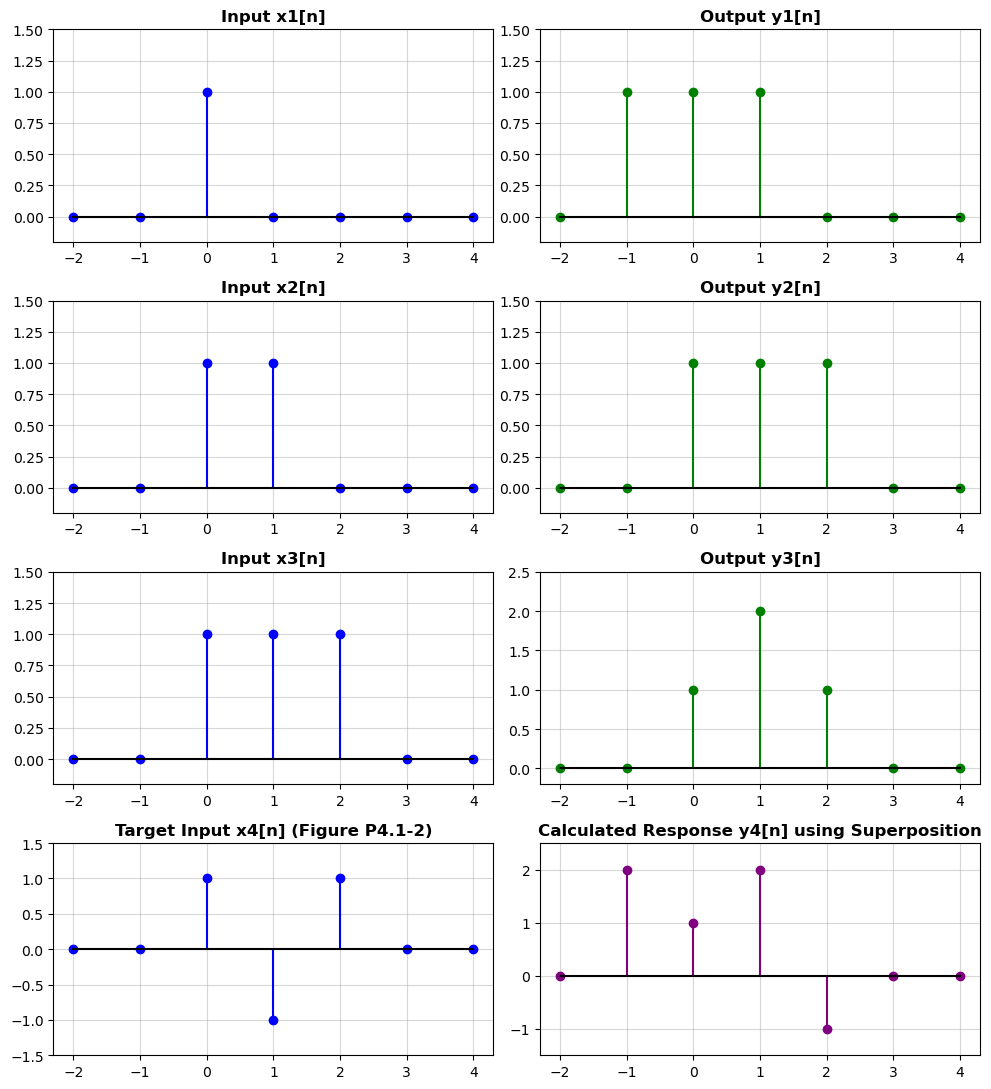


### **Step (a): Expressing $x_4[n]$ as a Linear Combination of $x_1[n], x_2[n], x_3[n]$**
From Figure P4.1-2, the target input signal $x_4[n]$ has values:
$$x_4[n] = \delta[n] - \delta[n-1] + \delta[n-2]$$

We express $x_4[n]$ as a linear combination:
$$x_4[n] = a \, x_1[n] + b \, x_2[n] + c \, x_3[n]$$
$$x_4[n] = a \delta[n] + b(\delta[n] + \delta[n-1]) + c(\delta[n] + \delta[n-1] + \delta[n-2])$$
$$x_4[n] = (a + b + c)\delta[n] + (b + c)\delta[n-1] + c\delta[n-2]$$

Matching coefficients with $x_4[n] = 1\delta[n] - 1\delta[n-1] + 1\delta[n-2]$:
1. $c = 1$
2. $b + c = -1 \implies b + 1 = -1 \implies b = -2$
3. $a + b + c = 1 \implies a - 2 + 1 = 1 \implies a - 1 = 1 \implies a = 2$

Thus, the linear combination is:
$$x_4[n] = 2 x_1[n] - 2 x_2[n] + x_3[n]$$

---

### **Step (b): Determining the Response $y_4[n]$ Using Superposition**
Since the system is linear, the output corresponding to the linear combination of inputs is the same linear combination of the outputs:
$$y_4[n] = 2 y_1[n] - 2 y_2[n] + y_3[n]$$

Calculating point by point:
* **At $n = -1$:** $y_4[-1] = 2(1) - 2(0) + 0 = 2$
* **At $n = 0$:** $y_4[0] = 2(1) - 2(1) + 1 = 2 - 2 + 1 = 1$
* **At $n = 1$:** $y_4[1] = 2(1) - 2(1) + 2 = 2 - 2 + 2 = 2$
* **At $n = 2$:** $y_4[2] = 2(0) - 2(1) + 1 = 0 - 2 + 1 = -1$
* **At $n = 3$:** $y_4[3] = 2(0) - 2(0) + 0 = 0$

### **Final Result:**
$$y_4[n] = \{2, 1, \underset{\uparrow}{1}, 2, -1\} \quad \text{for } n = -1, 0, 1, 2, 3$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

display(Markdown(r"""
# Problem P4.1: Superposition Principle in LTI Systems

### **Problem Statement:**
> Suppose that a discrete-time linear system has outputs $y[n]$ for the given inputs $x[n]$ as shown in Figure P4.1-1. Determine the response $y_4[n]$ when the input is as shown in Figure P4.1-2.

### **1. Given Input-Output Pairs (Figure P4.1-1):**
* **Input 1:** $x_1[n] = \delta[n]$ (at $n=0$, value = 1)
  * **Output 1:** $y_1[n] = \delta[n+1] + \delta[n] + \delta[n-1]$ (values 1 at $n = -1, 0, 1$)
* **Input 2:** $x_2[n] = \delta[n] + \delta[n-1]$ (values 1 at $n = 0, 1$)
  * **Output 2:** $y_2[n] = \delta[n] + \delta[n-1] + \delta[n-2]$ (values 1 at $n = 0, 1, 2$)
* **Input 3:** $x_3[n] = \delta[n] + \delta[n-1] + \delta[n-2]$ (values 1 at $n = 0, 1, 2$)
  * **Output 3:** $y_3[n] = \delta[n] + 2\delta[n-1] + \delta[n-2]$ (values: 1 at $n=0$, 2 at $n=1$, 1 at $n=2$)
---
"""))

# Plotting Input-Output pairs from Figure P4.1-1 and P4.1-2
n = np.arange(-2, 5)
x1 = np.where(n == 0, 1, 0)
y1 = np.where((n >= -1) & (n <= 1), 1, 0)

x2 = np.where((n >= 0) & (n <= 1), 1, 0)
y2 = np.where((n >= 0) & (n <= 2), 1, 0)

x3 = np.where((n >= 0) & (n <= 2), 1, 0)
y3 = np.where(n == 0, 1, np.where(n == 1, 2, np.where(n == 2, 1, 0)))

x4 = np.where(n == 0, 1, np.where(n == 1, -1, np.where(n == 2, 1, 0)))
y4 = 2 * y1 - 2 * y2 + y3

fig, axes = plt.subplots(4, 2, figsize=(10, 11))

# Row 1: x1, y1
axes[0, 0].stem(n, x1, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0, 0].set_title('Input x1[n]', fontweight='bold')
axes[0, 0].set_ylim(-0.2, 1.5)
axes[0, 0].grid(True, alpha=0.5)

axes[0, 1].stem(n, y1, linefmt='g-', markerfmt='go', basefmt='k-')
axes[0, 1].set_title('Output y1[n]', fontweight='bold')
axes[0, 1].set_ylim(-0.2, 1.5)
axes[0, 1].grid(True, alpha=0.5)

# Row 2: x2, y2
axes[1, 0].stem(n, x2, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[1, 0].set_title('Input x2[n]', fontweight='bold')
axes[1, 0].set_ylim(-0.2, 1.5)
axes[1, 0].grid(True, alpha=0.5)

axes[1, 1].stem(n, y2, linefmt='g-', markerfmt='go', basefmt='k-')
axes[1, 1].set_title('Output y2[n]', fontweight='bold')
axes[1, 1].set_ylim(-0.2, 1.5)
axes[1, 1].grid(True, alpha=0.5)

# Row 3: x3, y3
axes[2, 0].stem(n, x3, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[2, 0].set_title('Input x3[n]', fontweight='bold')
axes[2, 0].set_ylim(-0.2, 1.5)
axes[2, 0].grid(True, alpha=0.5)

axes[2, 1].stem(n, y3, linefmt='g-', markerfmt='go', basefmt='k-')
axes[2, 1].set_title('Output y3[n]', fontweight='bold')
axes[2, 1].set_ylim(-0.2, 2.5)
axes[2, 1].grid(True, alpha=0.5)

# Row 4: x4 and calculated y4
axes[3, 0].stem(n, x4, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[3, 0].set_title('Target Input x4[n] (Figure P4.1-2)', fontweight='bold')
axes[3, 0].set_ylim(-1.5, 1.5)
axes[3, 0].grid(True, alpha=0.5)

axes[3, 1].stem(n, y4, linefmt='purple', markerfmt='o', basefmt='k-')
axes[3, 1].set_title('Calculated Response y4[n] using Superposition', fontweight='bold')
axes[3, 1].set_ylim(-1.5, 2.5)
axes[3, 1].grid(True, alpha=0.5)

for ax_row in axes:
    for ax in ax_row:
        ax.set_xticks(n)

plt.tight_layout()
plt.show()

display(Markdown(r"""
### **Step (a): Expressing $x_4[n]$ as a Linear Combination of $x_1[n], x_2[n], x_3[n]$**
From Figure P4.1-2, the target input signal $x_4[n]$ has values:
$$x_4[n] = \delta[n] - \delta[n-1] + \delta[n-2]$$

We express $x_4[n]$ as a linear combination:
$$x_4[n] = a \, x_1[n] + b \, x_2[n] + c \, x_3[n]$$
$$x_4[n] = a \delta[n] + b(\delta[n] + \delta[n-1]) + c(\delta[n] + \delta[n-1] + \delta[n-2])$$
$$x_4[n] = (a + b + c)\delta[n] + (b + c)\delta[n-1] + c\delta[n-2]$$

Matching coefficients with $x_4[n] = 1\delta[n] - 1\delta[n-1] + 1\delta[n-2]$:
1. $c = 1$
2. $b + c = -1 \implies b + 1 = -1 \implies b = -2$
3. $a + b + c = 1 \implies a - 2 + 1 = 1 \implies a - 1 = 1 \implies a = 2$

Thus, the linear combination is:
$$x_4[n] = 2 x_1[n] - 2 x_2[n] + x_3[n]$$

---

### **Step (b): Determining the Response $y_4[n]$ Using Superposition**
Since the system is linear, the output corresponding to the linear combination of inputs is the same linear combination of the outputs:
$$y_4[n] = 2 y_1[n] - 2 y_2[n] + y_3[n]$$

Calculating point by point:
* **At $n = -1$:** $y_4[-1] = 2(1) - 2(0) + 0 = 2$
* **At $n = 0$:** $y_4[0] = 2(1) - 2(1) + 1 = 2 - 2 + 1 = 1$
* **At $n = 1$:** $y_4[1] = 2(1) - 2(1) + 2 = 2 - 2 + 2 = 2$
* **At $n = 2$:** $y_4[2] = 2(0) - 2(1) + 1 = 0 - 2 + 1 = -1$
* **At $n = 3$:** $y_4[3] = 2(0) - 2(0) + 0 = 0$

### **Final Result:**
$$y_4[n] = \{2, 1, \underset{\uparrow}{1}, 2, -1\} \quad \text{for } n = -1, 0, 1, 2, 3$$
"""))


# Problem 1: Discrete-Time Convolution (Figure P4.2-1)

### **Problem Statement:**
> **Determine the discrete-time convolution of $x[n]$ and $h[n]$ for case (a) shown in Figure P4.2-1.**

### **1. Mathematical Definition of the Given Signals:**
From Figure P4.2-1:
$$x[n] = \begin{cases} 1, & n = 0, 1, 2, 3 \\ 0, & \text{otherwise} \end{cases}, \qquad h[n] = \begin{cases} 2, & n = 0, 1, 2, 3 \\ 0, & \text{otherwise} \end{cases}$$


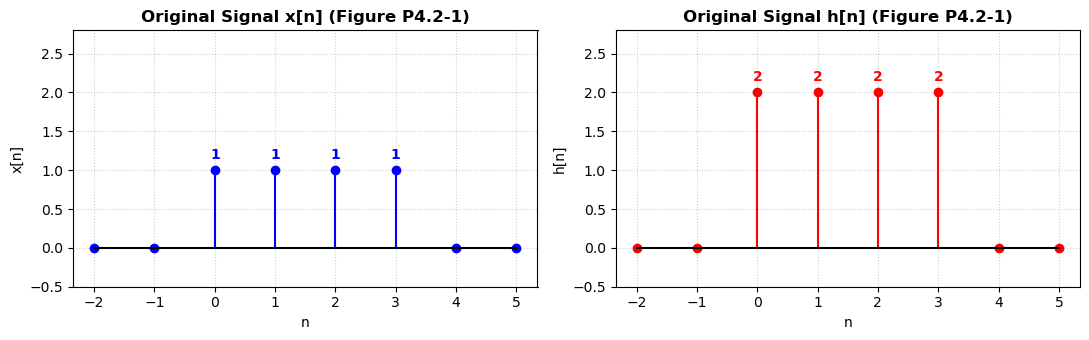

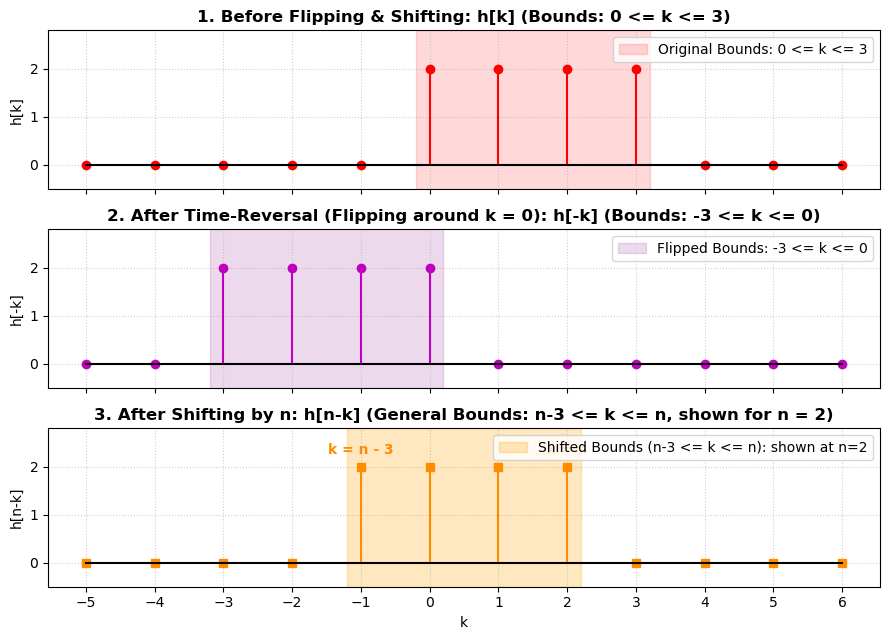


### **2. Algebraic Derivation of Signal Transformation (Before & After Shifting):**
To evaluate the convolution sum:
$$y[n] = x[n] * h[n] = \sum_{k=-\infty}^{\infty} x[k] \, h[n-k]$$

1. **Change of Index ($n \to k$):**
   * **Fixed Signal $x[k]$:** Remains stationary on the interval $0 \le k \le 3$ with amplitude $1$.
   * **Signal $h[k]$ (Before Flipping & Shifting):** Active on the interval $0 \le k \le 3$ with amplitude $2$.
2. **Time-Reversal / Flipping ($k \to -k$):**
   * Replace $k$ with $-k$ in the bounds of $h[k]$:
   $$0 \le -k \le 3 \implies \text{Multiply by } (-1) \implies -3 \le k \le 0$$
   * Thus, $h[-k]$ is active from $k = -3$ to $k = 0$.
3. **Time-Shifting ($-k \to n - k$):**
   * Replace $k$ with $n - k$ in the original bounds of $h$:
   $$0 \le n - k \le 3 \implies -n \le -k \le 3 - n \implies n - 3 \le k \le n$$
   * Thus, for any shift $n$, the moving signal $h[n-k]$ has its **left boundary at $k = n - 3$** and its **right boundary at $k = n$**.
---


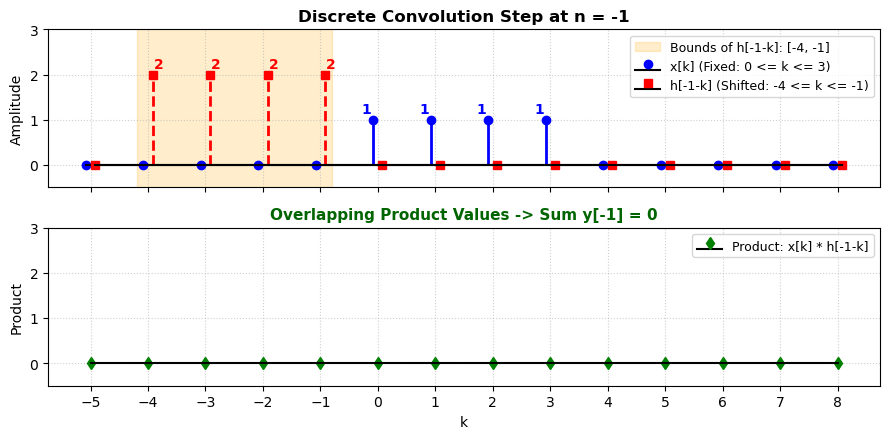


#### **Algebraic Step for $n < 0$ (Example: $n = -1$):**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[-1-k]$:** $-1 - 3 \le k \le -1 \implies -4 \le k \le -1$
* **Overlap Region:** Since $[-4, -1] \cap [0, 3] = \emptyset$, there is no overlap between the two signals.
$$y[-1] = \sum_{k=-\infty}^{\infty} x[k] \, h[-1-k] = 0 \implies y[n] = 0 \quad \text{for all } n < 0$$
---


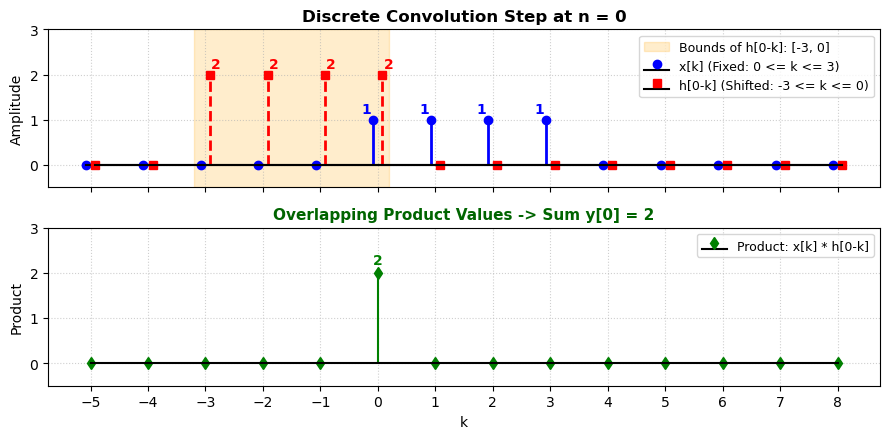


#### **Algebraic Step for $n = 0$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[0-k]$:** $0 - 3 \le k \le 0 \implies -3 \le k \le 0$
* **Overlap Region:** The signals overlap only at $k = 0$.
$$y[0] = \sum_{k=0}^{0} x[k] \, h[0-k] = x[0] \cdot h[0-0] = x[0] \cdot h[0]$$
* **Substitute values ($x[0]=1, h[0]=2$):**
$$y[0] = (1)(2) = 2$$
---


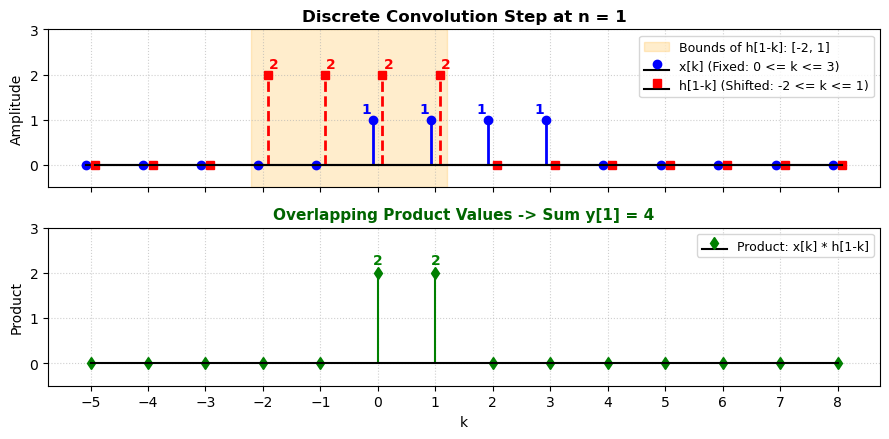


#### **Algebraic Step for $n = 1$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[1-k]$:** $1 - 3 \le k \le 1 \implies -2 \le k \le 1$
* **Overlap Region:** The signals overlap at $k = 0, 1$.
$$y[1] = \sum_{k=0}^{1} x[k] \, h[1-k] = x[0] \cdot h[1-0] + x[1] \cdot h[1-1] = x[0] \cdot h[1] + x[1] \cdot h[0]$$
* **Substitute values:**
$$y[1] = (1)(2) + (1)(2) = 2 + 2 = 4$$
---


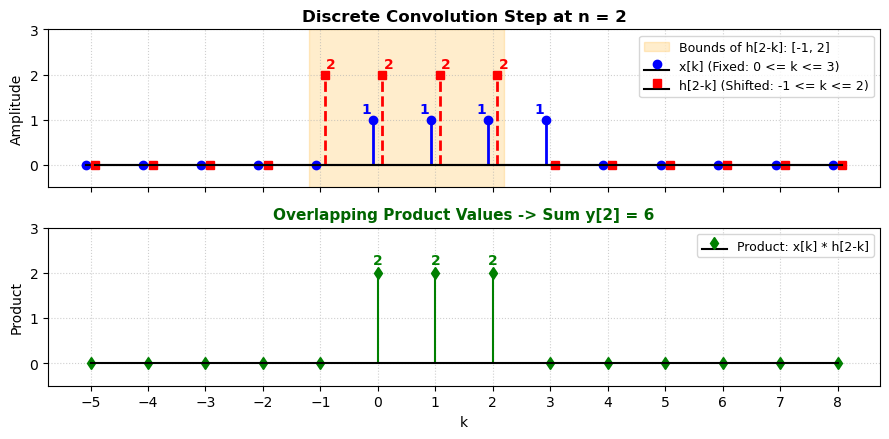


#### **Algebraic Step for $n = 2$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[2-k]$:** $2 - 3 \le k \le 2 \implies -1 \le k \le 2$
* **Overlap Region:** The signals overlap at $k = 0, 1, 2$.
$$y[2] = \sum_{k=0}^{2} x[k] \, h[2-k] = x[0] \cdot h[2] + x[1] \cdot h[1] + x[2] \cdot h[0]$$
* **Substitute values:**
$$y[2] = (1)(2) + (1)(2) + (1)(2) = 2 + 2 + 2 = 6$$
---


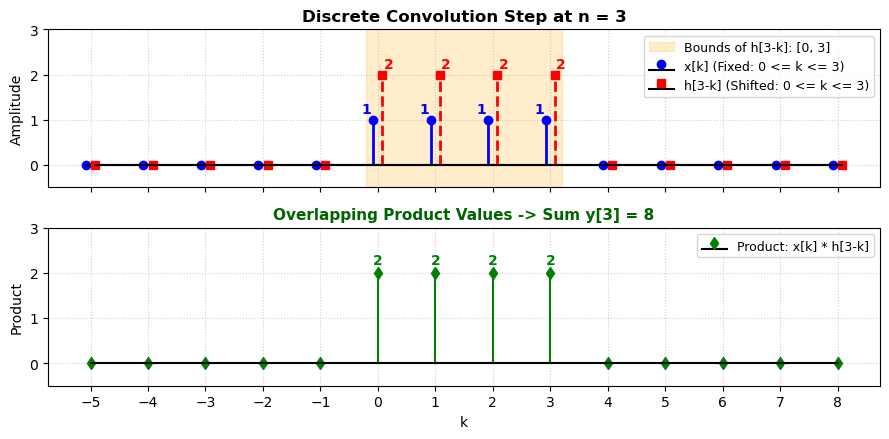


#### **Algebraic Step for $n = 3$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[3-k]$:** $3 - 3 \le k \le 3 \implies 0 \le k \le 3$
* **Overlap Region:** Full overlap at $k = 0, 1, 2, 3$.
$$y[3] = \sum_{k=0}^{3} x[k] \, h[3-k] = x[0] \cdot h[3] + x[1] \cdot h[2] + x[2] \cdot h[1] + x[3] \cdot h[0]$$
* **Substitute values:**
$$y[3] = (1)(2) + (1)(2) + (1)(2) + (1)(2) = 2 + 2 + 2 + 2 = 8$$
---


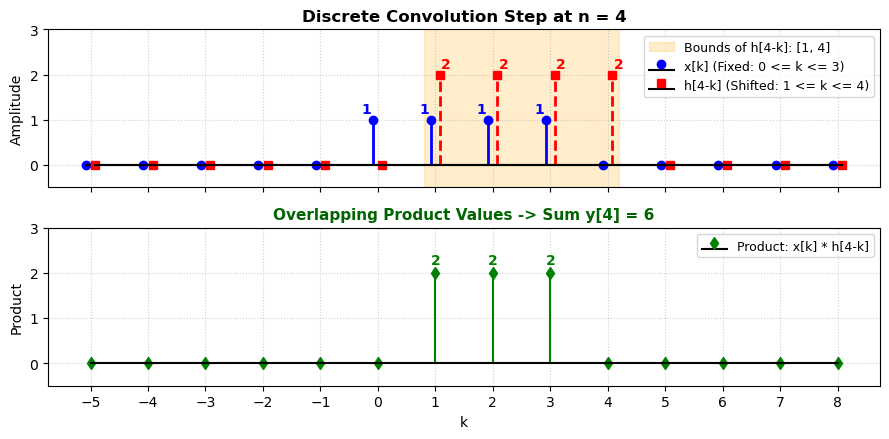


#### **Algebraic Step for $n = 4$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[4-k]$:** $4 - 3 \le k \le 4 \implies 1 \le k \le 4$
* **Overlap Region:** The signals overlap at $k = 1, 2, 3$.
$$y[4] = \sum_{k=1}^{3} x[k] \, h[4-k] = x[1] \cdot h[4-1] + x[2] \cdot h[4-2] + x[3] \cdot h[4-3]$$
$$y[4] = x[1] \cdot h[3] + x[2] \cdot h[2] + x[3] \cdot h[1]$$
* **Substitute values:**
$$y[4] = (1)(2) + (1)(2) + (1)(2) = 2 + 2 + 2 = 6$$
---


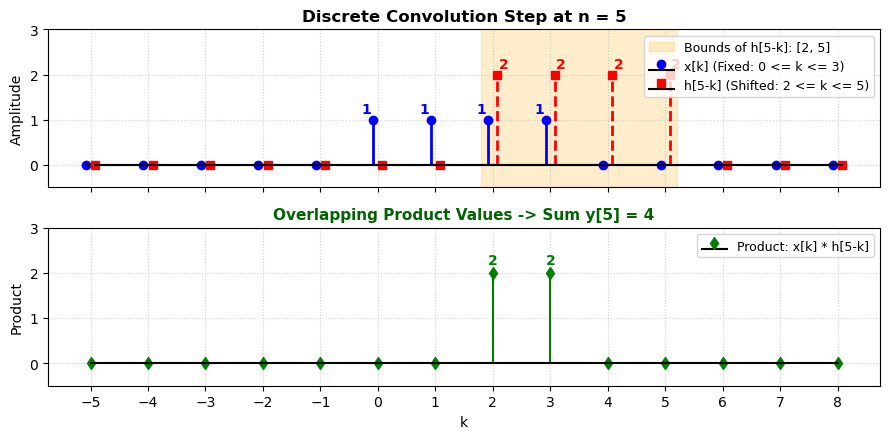


#### **Algebraic Step for $n = 5$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[5-k]$:** $5 - 3 \le k \le 5 \implies 2 \le k \le 5$
* **Overlap Region:** The signals overlap at $k = 2, 3$.
$$y[5] = \sum_{k=2}^{3} x[k] \, h[5-k] = x[2] \cdot h[5-2] + x[3] \cdot h[5-3] = x[2] \cdot h[3] + x[3] \cdot h[2]$$
* **Substitute values:**
$$y[5] = (1)(2) + (1)(2) = 2 + 2 = 4$$
---


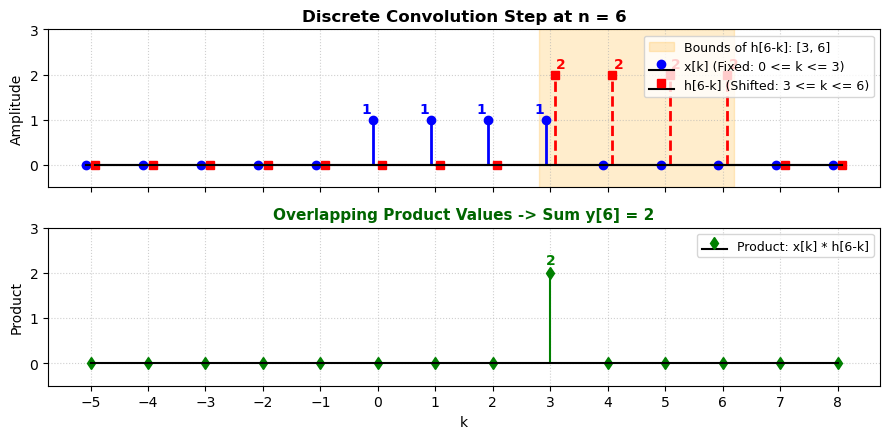


#### **Algebraic Step for $n = 6$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[6-k]$:** $6 - 3 \le k \le 6 \implies 3 \le k \le 6$
* **Overlap Region:** The signals overlap only at $k = 3$.
$$y[6] = \sum_{k=3}^{3} x[k] \, h[6-k] = x[3] \cdot h[6-3] = x[3] \cdot h[3]$$
* **Substitute values:**
$$y[6] = (1)(2) = 2$$
---


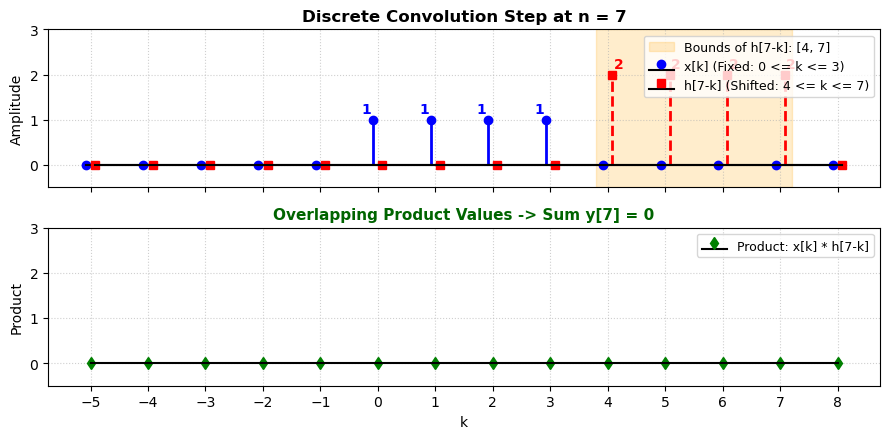


#### **Algebraic Step for $n > 6$ (Example: $n = 7$):**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[7-k]$:** $7 - 3 \le k \le 7 \implies 4 \le k \le 7$
* **Overlap Region:** Since $[0, 3] \cap [4, 7] = \emptyset$, there is no overlap.
$$y[7] = \sum_{k=-\infty}^{\infty} x[k] \, h[7-k] = 0 \implies y[n] = 0 \quad \text{for all } n > 6$$
---


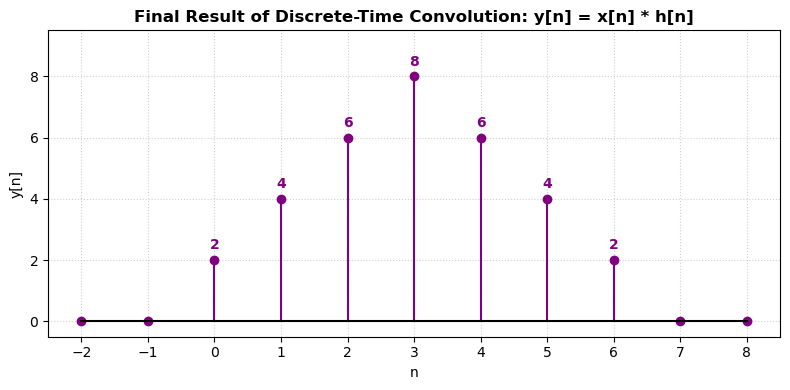


#### **Final Algebraic Summary for Problem 1:**
$$y[n] = \begin{cases} 
2, & n = 0, 6 \\
4, & n = 1, 5 \\
6, & n = 2, 4 \\
8, & n = 3 \\
0, & \text{otherwise}
\end{cases} \implies y[n] = \{ \underset{\uparrow}{2}, 4, 6, 8, 6, 4, 2 \}$$
---
---



# Problem 2: Continuous-Time Convolution (Figure P4.3-1)

### **Problem Statement:**
> **Determine the continuous-time convolution of $x(t)$ and $h(t)$ for case (a) shown in Figure P4.3-1.**

### **1. Mathematical Definition of the Given Signals:**
From Figure P4.3-1:
$$x(t) = \begin{cases} 1, & 0 \le t \le 4 \\ 0, & \text{otherwise} \end{cases}, \qquad h(t) = \begin{cases} 1, & 0 \le t \le 4 \\ 0, & \text{otherwise} \end{cases}$$


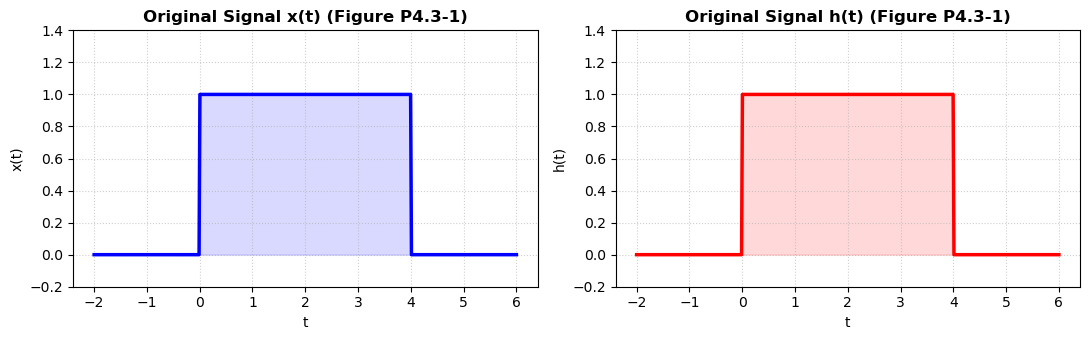

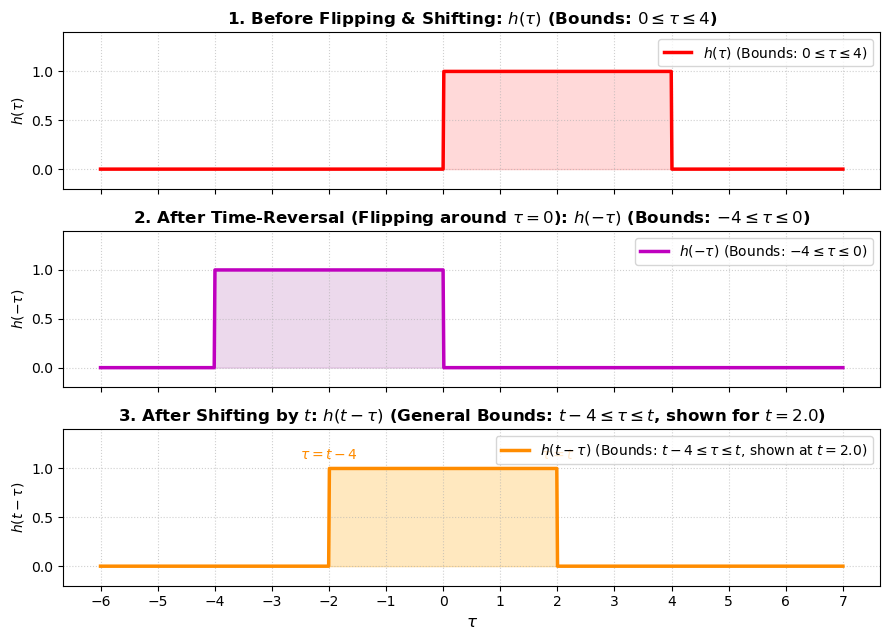


### **2. Algebraic Derivation of Signal Transformation (Before & After Shifting):**
To evaluate the convolution integral:
$$y(t) = x(t) * h(t) = \int_{-\infty}^{\infty} x(\tau) \, h(t-\tau) \, d\tau$$

1. **Change of Variable ($t \to \tau$):**
   * **Fixed Signal $x(\tau)$:** Remains stationary on the interval $0 \le \tau \le 4$ with amplitude $1$.
   * **Signal $h(\tau)$ (Before Flipping & Shifting):** Active on the interval $0 \le \tau \le 4$ with amplitude $1$.
2. **Time-Reversal / Flipping ($\tau \to -\tau$):**
   * Replace $\tau$ with $-\tau$ in the bounds of $h(\tau)$:
   $$0 \le -\tau \le 4 \implies \text{Multiply by } (-1) \implies -4 \le \tau \le 0$$
   * Thus, $h(-\tau)$ is flipped across the vertical axis $\tau = 0$.
3. **Time-Shifting ($-\tau \to t - \tau$):**
   * Replace $\tau$ with $t - \tau$ in the original bounds of $h$:
   $$0 \le t - \tau \le 4 \implies -t \le -\tau \le 4 - t \implies t - 4 \le \tau \le t$$
   * Thus, the moving pulse $h(t-\tau)$ has its **trailing (left) edge at $\tau = t - 4$** and its **leading (right) edge at $\tau = t$**.
---


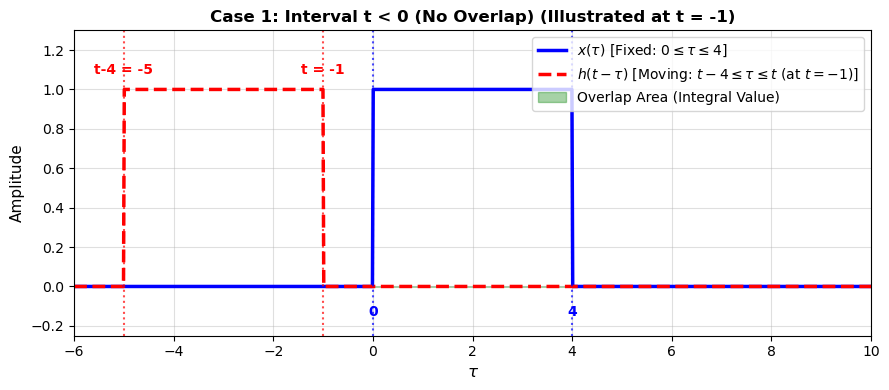


#### **Algebraic Step for Case 1 ($t < 0$):**
* **Fixed Bounds of $x(\tau)$:** $0 \le \tau \le 4$
* **Moving Bounds of $h(t-\tau)$:** $t - 4 \le \tau \le t$
* **Condition:** Since the leading edge of $h(t-\tau)$ is to the left of $x(\tau)$ (i.e., $t < 0$), the two pulses do not intersect:
$$y(t) = \int_{-\infty}^{\infty} x(\tau) \, h(t-\tau) \, d\tau = \int_{-\infty}^{\infty} 0 \, d\tau = 0 \quad \text{for } t < 0$$
---


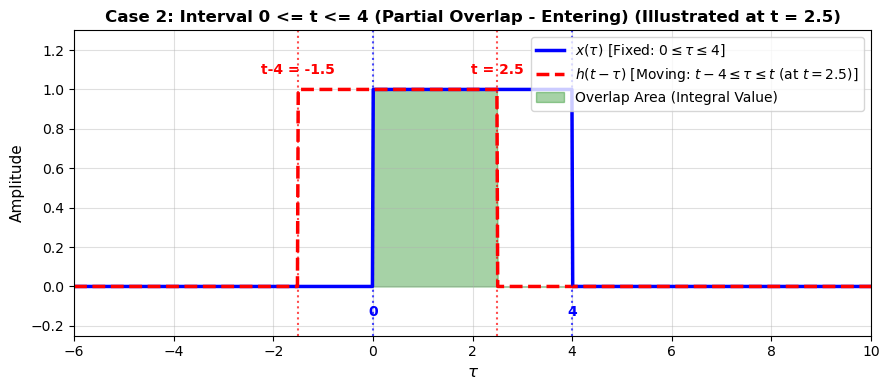


#### **Algebraic Step for Case 2 ($0 \le t \le 4$):**
* **Condition:** The leading edge $\tau = t$ has entered the fixed interval $[0, 4]$ ($t \ge 0$), while the trailing edge $\tau = t - 4$ is still outside to the left ($t - 4 \le 0 \implies t \le 4$).
* **Combined Interval:** $0 \le t \le 4$.
* **Limits of Integration:** The overlap starts at the left boundary of $x(\tau)$ ($\tau = 0$) and ends at the leading edge of $h(t-\tau)$ ($\tau = t$).
* **Substitute $x(\tau) = 1$ and $h(t-\tau) = 1$ into the integral:**
$$y(t) = \int_{0}^{t} x(\tau) \, h(t-\tau) \, d\tau = \int_{0}^{t} (1)(1) \, d\tau = \int_{0}^{t} 1 \, d\tau$$
$$y(t) = \Big[ \tau \Big]_{\tau=0}^{\tau=t} = t - 0 = t \quad \text{for } 0 \le t \le 4$$
---


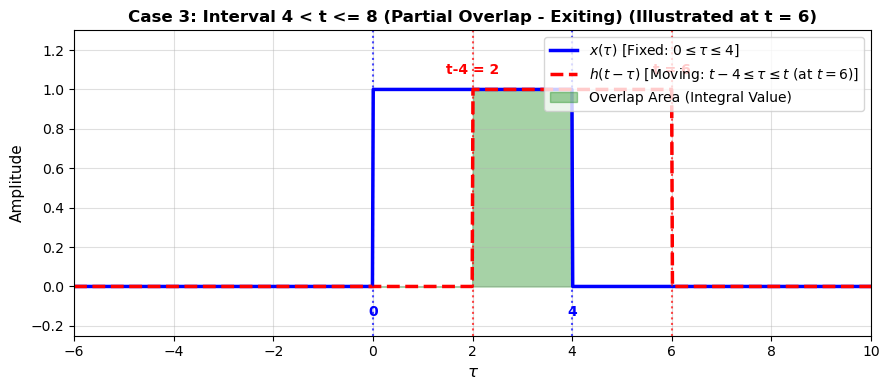


#### **Algebraic Step for Case 3 ($4 < t \le 8$):**
* **Condition:** The leading edge $\tau = t$ has passed the right boundary of $x(\tau)$ ($t > 4$), while the trailing edge $\tau = t - 4$ is inside the interval $[0, 4]$ ($0 < t - 4 \le 4 \implies 4 < t \le 8$).
* **Combined Interval:** $4 < t \le 8$.
* **Limits of Integration:** The overlap starts at the trailing edge of $h(t-\tau)$ ($\tau = t - 4$) and ends at the right boundary of $x(\tau)$ ($\tau = 4$).
* **Substitute $x(\tau) = 1$ and $h(t-\tau) = 1$ into the integral:**
$$y(t) = \int_{t-4}^{4} x(\tau) \, h(t-\tau) \, d\tau = \int_{t-4}^{4} (1)(1) \, d\tau = \int_{t-4}^{4} 1 \, d\tau$$
$$y(t) = \Big[ \tau \Big]_{\tau=t-4}^{\tau=4} = 4 - (t - 4) = 4 - t + 4 = 8 - t \quad \text{for } 4 < t \le 8$$
---


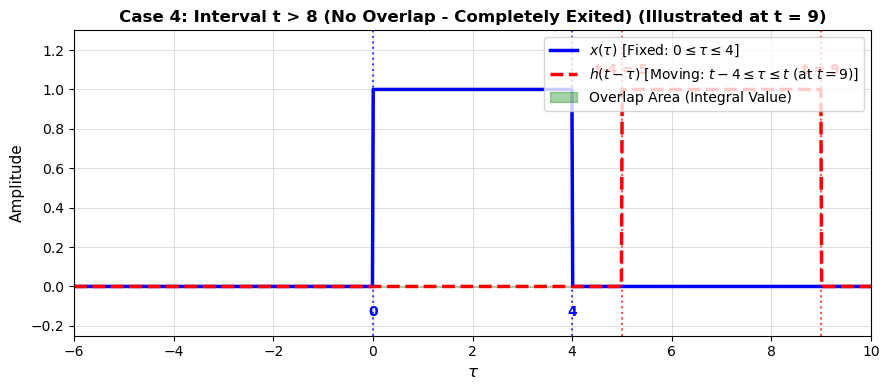


#### **Algebraic Step for Case 4 ($t > 8$):**
* **Condition:** The trailing edge $\tau = t - 4$ has completely passed the right boundary of $x(\tau)$ at $\tau = 4$ (i.e., $t - 4 > 4 \implies t > 8$).
* **Overlap:** No overlap exists between $x(\tau)$ and $h(t-\tau)$.
$$y(t) = \int_{-\infty}^{\infty} x(\tau) \, h(t-\tau) \, d\tau = \int_{-\infty}^{\infty} 0 \, d\tau = 0 \quad \text{for } t > 8$$
---


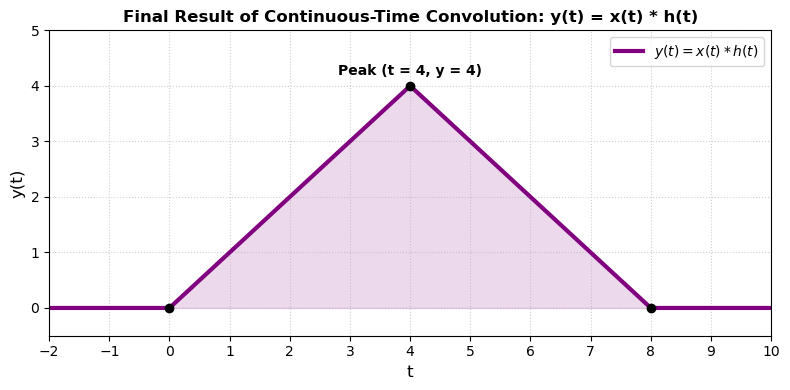


#### **Final Algebraic Summary for Problem 2:**
$$y(t) = \begin{cases} 
0, & t < 0 \\ 
t, & 0 \le t \le 4 \\ 
8 - t, & 4 < t \le 8 \\ 
0, & t > 8 
\end{cases}$$


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ==============================================================================
# PART 1: DISCRETE-TIME CONVOLUTION (Figure P4.2-1)
# ==============================================================================

display(Markdown(r"""
# Problem 1: Discrete-Time Convolution (Figure P4.2-1)

### **Problem Statement:**
> **Determine the discrete-time convolution of $x[n]$ and $h[n]$ for case (a) shown in Figure P4.2-1.**

### **1. Mathematical Definition of the Given Signals:**
From Figure P4.2-1:
$$x[n] = \begin{cases} 1, & n = 0, 1, 2, 3 \\ 0, & \text{otherwise} \end{cases}, \qquad h[n] = \begin{cases} 2, & n = 0, 1, 2, 3 \\ 0, & \text{otherwise} \end{cases}$$
"""))

# 1.1 Plot Original Signals x[n] and h[n]
n_orig = np.arange(-2, 6)
x_orig = np.where((n_orig >= 0) & (n_orig <= 3), 1, 0)
h_orig = np.where((n_orig >= 0) & (n_orig <= 3), 2, 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))

ax1.stem(n_orig, x_orig, linefmt='b-', markerfmt='bo', basefmt='k-')
for ni, xi in zip(n_orig, x_orig):
    if xi > 0:
        ax1.text(ni, xi + 0.15, f'{xi}', ha='center', color='blue', fontweight='bold')
ax1.set_title('Original Signal x[n] (Figure P4.2-1)', fontweight='bold')
ax1.set_xlabel('n')
ax1.set_ylabel('x[n]')
ax1.set_ylim(-0.5, 2.8)
ax1.set_xticks(n_orig)
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.stem(n_orig, h_orig, linefmt='r-', markerfmt='ro', basefmt='k-')
for ni, hi in zip(n_orig, h_orig):
    if hi > 0:
        ax2.text(ni, hi + 0.15, f'{hi}', ha='center', color='red', fontweight='bold')
ax2.set_title('Original Signal h[n] (Figure P4.2-1)', fontweight='bold')
ax2.set_xlabel('n')
ax2.set_ylabel('h[n]')
ax2.set_ylim(-0.5, 2.8)
ax2.set_xticks(n_orig)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 1.2 Plot Signals Before and After Flipping & Shifting
k_trans = np.arange(-5, 7)
h_k_before = np.where((k_trans >= 0) & (k_trans <= 3), 2, 0)
h_k_flipped = np.where((k_trans >= -3) & (k_trans <= 0), 2, 0)
n_demo = 2  # Example shift n = 2 to illustrate h[n-k]
h_k_shifted = np.where((k_trans >= n_demo - 3) & (k_trans <= n_demo), 2, 0)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)

# Before Flipping & Shifting: h[k]
ax1.stem(k_trans, h_k_before, linefmt='r-', markerfmt='ro', basefmt='k-')
ax1.axvspan(-0.2, 3.2, color='red', alpha=0.15, label='Original Bounds: 0 <= k <= 3')
ax1.set_title('1. Before Flipping & Shifting: h[k] (Bounds: 0 <= k <= 3)', fontweight='bold')
ax1.set_ylabel('h[k]')
ax1.set_ylim(-0.5, 2.8)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# After Time-Reversal (Flipping): h[-k]
ax2.stem(k_trans, h_k_flipped, linefmt='m-', markerfmt='mo', basefmt='k-')
ax2.axvspan(-3.2, 0.2, color='purple', alpha=0.15, label='Flipped Bounds: -3 <= k <= 0')
ax2.set_title('2. After Time-Reversal (Flipping around k = 0): h[-k] (Bounds: -3 <= k <= 0)', fontweight='bold')
ax2.set_ylabel('h[-k]')
ax2.set_ylim(-0.5, 2.8)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

# After Time-Shifting by n: h[n-k]
ax3.stem(k_trans, h_k_shifted, linefmt='darkorange', markerfmt='s', basefmt='k-')
ax3.axvspan(n_demo - 3 - 0.2, n_demo + 0.2, color='orange', alpha=0.25, label=f'Shifted Bounds (n-3 <= k <= n): shown at n={n_demo}')
ax3.text(n_demo - 3, 2.25, 'k = n - 3', ha='center', color='darkorange', fontweight='bold')
ax3.text(n_demo, 2.25, 'k = n', ha='center', color='darkorange', fontweight='bold')
ax3.set_title(f'3. After Shifting by n: h[n-k] (General Bounds: n-3 <= k <= n, shown for n = {n_demo})', fontweight='bold')
ax3.set_xlabel('k')
ax3.set_ylabel('h[n-k]')
ax3.set_ylim(-0.5, 2.8)
ax3.set_xticks(k_trans)
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(loc='upper right')

plt.tight_layout()
plt.show()

display(Markdown(r"""
### **2. Algebraic Derivation of Signal Transformation (Before & After Shifting):**
To evaluate the convolution sum:
$$y[n] = x[n] * h[n] = \sum_{k=-\infty}^{\infty} x[k] \, h[n-k]$$

1. **Change of Index ($n \to k$):**
   * **Fixed Signal $x[k]$:** Remains stationary on the interval $0 \le k \le 3$ with amplitude $1$.
   * **Signal $h[k]$ (Before Flipping & Shifting):** Active on the interval $0 \le k \le 3$ with amplitude $2$.
2. **Time-Reversal / Flipping ($k \to -k$):**
   * Replace $k$ with $-k$ in the bounds of $h[k]$:
   $$0 \le -k \le 3 \implies \text{Multiply by } (-1) \implies -3 \le k \le 0$$
   * Thus, $h[-k]$ is active from $k = -3$ to $k = 0$.
3. **Time-Shifting ($-k \to n - k$):**
   * Replace $k$ with $n - k$ in the original bounds of $h$:
   $$0 \le n - k \le 3 \implies -n \le -k \le 3 - n \implies n - 3 \le k \le n$$
   * Thus, for any shift $n$, the moving signal $h[n-k]$ has its **left boundary at $k = n - 3$** and its **right boundary at $k = n$**.
---
"""))

def plot_discrete_step(n_val):
    k = np.arange(-5, 9)
    x_k = np.where((k >= 0) & (k <= 3), 1, 0)
    h_nk = np.where((k >= n_val - 3) & (k <= n_val), 2, 0)
    prod = x_k * h_nk
    y_n = np.sum(prod)
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
    
    # Top Plot: Overlap between x[k] and h[n-k]
    m1, s1, b1 = ax1.stem(k - 0.08, x_k, linefmt='b-', markerfmt='bo', basefmt='k-', label='x[k] (Fixed: 0 <= k <= 3)')
    m2, s2, b2 = ax1.stem(k + 0.08, h_nk, linefmt='r--', markerfmt='rs', basefmt='k-', label=f'h[{n_val}-k] (Shifted: {n_val-3} <= k <= {n_val})')
    plt.setp(s1, 'linewidth', 2)
    plt.setp(s2, 'linewidth', 2)
    
    ax1.axvspan(n_val - 3 - 0.2, n_val + 0.2, color='orange', alpha=0.2, label=f'Bounds of h[{n_val}-k]: [{n_val-3}, {n_val}]')
    ax1.set_title(f'Discrete Convolution Step at n = {n_val}', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Amplitude')
    ax1.set_ylim(-0.5, 3)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(loc='upper right', fontsize=9)
    
    for ki, xi, hi in zip(k, x_k, h_nk):
        if xi > 0:
            ax1.text(ki - 0.28, xi + 0.15, f'{xi}', color='blue', fontweight='bold')
        if hi > 0:
            ax1.text(ki + 0.1, hi + 0.15, f'{hi}', color='red', fontweight='bold')

    # Bottom Plot: Product x[k] * h[n-k]
    ax2.stem(k, prod, linefmt='g-', markerfmt='gd', basefmt='k-', label=f'Product: x[k] * h[{n_val}-k]')
    for ki, pi in zip(k, prod):
        if pi > 0:
            ax2.text(ki, pi + 0.2, f'{pi}', color='green', fontweight='bold', ha='center')
            
    ax2.set_title(f'Overlapping Product Values -> Sum y[{n_val}] = {y_n}', fontsize=11, fontweight='bold', color='darkgreen')
    ax2.set_xlabel('k')
    ax2.set_ylabel('Product')
    ax2.set_ylim(-0.5, 3)
    ax2.set_xticks(k)
    ax2.grid(True, linestyle=':', alpha=0.6)
    ax2.legend(loc='upper right', fontsize=9)
    
    plt.tight_layout()
    plt.show()

discrete_explanations = {
    -1: r"""
#### **Algebraic Step for $n < 0$ (Example: $n = -1$):**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[-1-k]$:** $-1 - 3 \le k \le -1 \implies -4 \le k \le -1$
* **Overlap Region:** Since $[-4, -1] \cap [0, 3] = \emptyset$, there is no overlap between the two signals.
$$y[-1] = \sum_{k=-\infty}^{\infty} x[k] \, h[-1-k] = 0 \implies y[n] = 0 \quad \text{for all } n < 0$$
---
""",
    0: r"""
#### **Algebraic Step for $n = 0$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[0-k]$:** $0 - 3 \le k \le 0 \implies -3 \le k \le 0$
* **Overlap Region:** The signals overlap only at $k = 0$.
$$y[0] = \sum_{k=0}^{0} x[k] \, h[0-k] = x[0] \cdot h[0-0] = x[0] \cdot h[0]$$
* **Substitute values ($x[0]=1, h[0]=2$):**
$$y[0] = (1)(2) = 2$$
---
""",
    1: r"""
#### **Algebraic Step for $n = 1$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[1-k]$:** $1 - 3 \le k \le 1 \implies -2 \le k \le 1$
* **Overlap Region:** The signals overlap at $k = 0, 1$.
$$y[1] = \sum_{k=0}^{1} x[k] \, h[1-k] = x[0] \cdot h[1-0] + x[1] \cdot h[1-1] = x[0] \cdot h[1] + x[1] \cdot h[0]$$
* **Substitute values:**
$$y[1] = (1)(2) + (1)(2) = 2 + 2 = 4$$
---
""",
    2: r"""
#### **Algebraic Step for $n = 2$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[2-k]$:** $2 - 3 \le k \le 2 \implies -1 \le k \le 2$
* **Overlap Region:** The signals overlap at $k = 0, 1, 2$.
$$y[2] = \sum_{k=0}^{2} x[k] \, h[2-k] = x[0] \cdot h[2] + x[1] \cdot h[1] + x[2] \cdot h[0]$$
* **Substitute values:**
$$y[2] = (1)(2) + (1)(2) + (1)(2) = 2 + 2 + 2 = 6$$
---
""",
    3: r"""
#### **Algebraic Step for $n = 3$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[3-k]$:** $3 - 3 \le k \le 3 \implies 0 \le k \le 3$
* **Overlap Region:** Full overlap at $k = 0, 1, 2, 3$.
$$y[3] = \sum_{k=0}^{3} x[k] \, h[3-k] = x[0] \cdot h[3] + x[1] \cdot h[2] + x[2] \cdot h[1] + x[3] \cdot h[0]$$
* **Substitute values:**
$$y[3] = (1)(2) + (1)(2) + (1)(2) + (1)(2) = 2 + 2 + 2 + 2 = 8$$
---
""",
    4: r"""
#### **Algebraic Step for $n = 4$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[4-k]$:** $4 - 3 \le k \le 4 \implies 1 \le k \le 4$
* **Overlap Region:** The signals overlap at $k = 1, 2, 3$.
$$y[4] = \sum_{k=1}^{3} x[k] \, h[4-k] = x[1] \cdot h[4-1] + x[2] \cdot h[4-2] + x[3] \cdot h[4-3]$$
$$y[4] = x[1] \cdot h[3] + x[2] \cdot h[2] + x[3] \cdot h[1]$$
* **Substitute values:**
$$y[4] = (1)(2) + (1)(2) + (1)(2) = 2 + 2 + 2 = 6$$
---
""",
    5: r"""
#### **Algebraic Step for $n = 5$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[5-k]$:** $5 - 3 \le k \le 5 \implies 2 \le k \le 5$
* **Overlap Region:** The signals overlap at $k = 2, 3$.
$$y[5] = \sum_{k=2}^{3} x[k] \, h[5-k] = x[2] \cdot h[5-2] + x[3] \cdot h[5-3] = x[2] \cdot h[3] + x[3] \cdot h[2]$$
* **Substitute values:**
$$y[5] = (1)(2) + (1)(2) = 2 + 2 = 4$$
---
""",
    6: r"""
#### **Algebraic Step for $n = 6$:**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[6-k]$:** $6 - 3 \le k \le 6 \implies 3 \le k \le 6$
* **Overlap Region:** The signals overlap only at $k = 3$.
$$y[6] = \sum_{k=3}^{3} x[k] \, h[6-k] = x[3] \cdot h[6-3] = x[3] \cdot h[3]$$
* **Substitute values:**
$$y[6] = (1)(2) = 2$$
---
""",
    7: r"""
#### **Algebraic Step for $n > 6$ (Example: $n = 7$):**
* **Bounds of $x[k]$:** $0 \le k \le 3$
* **Bounds of $h[7-k]$:** $7 - 3 \le k \le 7 \implies 4 \le k \le 7$
* **Overlap Region:** Since $[0, 3] \cap [4, 7] = \emptyset$, there is no overlap.
$$y[7] = \sum_{k=-\infty}^{\infty} x[k] \, h[7-k] = 0 \implies y[n] = 0 \quad \text{for all } n > 6$$
---
"""
}

for n_step in range(-1, 8):
    plot_discrete_step(n_step)
    display(Markdown(discrete_explanations[n_step]))

# Final Discrete Convolution Plot
n_final = np.arange(-2, 9)
y_final = np.array([0, 0, 2, 4, 6, 8, 6, 4, 2, 0, 0])

plt.figure(figsize=(8, 4))
plt.stem(n_final, y_final, linefmt='purple', markerfmt='o', basefmt='k-')
for ni, yi in zip(n_final, y_final):
    if yi > 0:
        plt.text(ni, yi + 0.35, f'{yi}', ha='center', fontweight='bold', color='purple')
plt.title('Final Result of Discrete-Time Convolution: y[n] = x[n] * h[n]', fontweight='bold')
plt.xlabel('n')
plt.ylabel('y[n]')
plt.ylim(-0.5, 9.5)
plt.xticks(n_final)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

display(Markdown(r"""
#### **Final Algebraic Summary for Problem 1:**
$$y[n] = \begin{cases} 
2, & n = 0, 6 \\
4, & n = 1, 5 \\
6, & n = 2, 4 \\
8, & n = 3 \\
0, & \text{otherwise}
\end{cases} \implies y[n] = \{ \underset{\uparrow}{2}, 4, 6, 8, 6, 4, 2 \}$$
---
---
"""))


# ==============================================================================
# PART 2: CONTINUOUS-TIME CONVOLUTION (Figure P4.3-1)
# ==============================================================================

display(Markdown(r"""
# Problem 2: Continuous-Time Convolution (Figure P4.3-1)

### **Problem Statement:**
> **Determine the continuous-time convolution of $x(t)$ and $h(t)$ for case (a) shown in Figure P4.3-1.**

### **1. Mathematical Definition of the Given Signals:**
From Figure P4.3-1:
$$x(t) = \begin{cases} 1, & 0 \le t \le 4 \\ 0, & \text{otherwise} \end{cases}, \qquad h(t) = \begin{cases} 1, & 0 \le t \le 4 \\ 0, & \text{otherwise} \end{cases}$$
"""))

# 2.1 Plot Original Signals x(t) and h(t)
t_orig = np.linspace(-2, 6, 500)
x_t_orig = np.where((t_orig >= 0) & (t_orig <= 4), 1.0, 0.0)
h_t_orig = np.where((t_orig >= 0) & (t_orig <= 4), 1.0, 0.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))

ax1.plot(t_orig, x_t_orig, 'b-', linewidth=2.5)
ax1.fill_between(t_orig, 0, x_t_orig, color='blue', alpha=0.15)
ax1.set_title('Original Signal x(t) (Figure P4.3-1)', fontweight='bold')
ax1.set_xlabel('t')
ax1.set_ylabel('x(t)')
ax1.set_ylim(-0.2, 1.4)
ax1.set_xticks(range(-2, 7))
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(t_orig, h_t_orig, 'r-', linewidth=2.5)
ax2.fill_between(t_orig, 0, h_t_orig, color='red', alpha=0.15)
ax2.set_title('Original Signal h(t) (Figure P4.3-1)', fontweight='bold')
ax2.set_xlabel('t')
ax2.set_ylabel('h(t)')
ax2.set_ylim(-0.2, 1.4)
ax2.set_xticks(range(-2, 7))
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 2.2 Plot Signals Before and After Flipping & Shifting on tau-axis
tau_trans = np.linspace(-6, 7, 1000)
h_tau_before = np.where((tau_trans >= 0) & (tau_trans <= 4), 1.0, 0.0)
h_tau_flipped = np.where((tau_trans >= -4) & (tau_trans <= 0), 1.0, 0.0)
t_demo = 2.0  # Example shift t = 2 to illustrate h(t - tau)
h_tau_shifted = np.where((tau_trans >= t_demo - 4) & (tau_trans <= t_demo), 1.0, 0.0)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)

# Before Flipping & Shifting: h(tau)
ax1.plot(tau_trans, h_tau_before, 'r-', linewidth=2.5, label=r'$h(\tau)$ (Bounds: $0 \leq \tau \leq 4$)')
ax1.fill_between(tau_trans, 0, h_tau_before, color='red', alpha=0.15)
ax1.set_title(r'1. Before Flipping & Shifting: $h(\tau)$ (Bounds: $0 \leq \tau \leq 4$)', fontweight='bold')
ax1.set_ylabel(r'$h(\tau)$')
ax1.set_ylim(-0.2, 1.4)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# After Time-Reversal (Flipping): h(-tau)
ax2.plot(tau_trans, h_tau_flipped, 'm-', linewidth=2.5, label=r'$h(-\tau)$ (Bounds: $-4 \leq \tau \leq 0$)')
ax2.fill_between(tau_trans, 0, h_tau_flipped, color='purple', alpha=0.15)
ax2.set_title(r'2. After Time-Reversal (Flipping around $\tau = 0$): $h(-\tau)$ (Bounds: $-4 \leq \tau \leq 0$)', fontweight='bold')
ax2.set_ylabel(r'$h(-\tau)$')
ax2.set_ylim(-0.2, 1.4)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

# After Time-Shifting by t: h(t - tau)
ax3.plot(tau_trans, h_tau_shifted, color='darkorange', linewidth=2.5, label=rf'$h(t-\tau)$ (Bounds: $t-4 \leq \tau \leq t$, shown at $t={t_demo}$)')
ax3.fill_between(tau_trans, 0, h_tau_shifted, color='orange', alpha=0.25)
ax3.text(t_demo - 4, 1.1, r'$\tau = t - 4$', ha='center', color='darkorange', fontweight='bold')
ax3.text(t_demo, 1.1, r'$\tau = t$', ha='center', color='darkorange', fontweight='bold')
ax3.set_title(rf'3. After Shifting by $t$: $h(t-\tau)$ (General Bounds: $t-4 \leq \tau \leq t$, shown for $t = {t_demo}$)', fontweight='bold')
ax3.set_xlabel(r'$\tau$', fontsize=12)
ax3.set_ylabel(r'$h(t-\tau)$')
ax3.set_ylim(-0.2, 1.4)
ax3.set_xticks(range(-6, 8))
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(loc='upper right')

plt.tight_layout()
plt.show()

display(Markdown(r"""
### **2. Algebraic Derivation of Signal Transformation (Before & After Shifting):**
To evaluate the convolution integral:
$$y(t) = x(t) * h(t) = \int_{-\infty}^{\infty} x(\tau) \, h(t-\tau) \, d\tau$$

1. **Change of Variable ($t \to \tau$):**
   * **Fixed Signal $x(\tau)$:** Remains stationary on the interval $0 \le \tau \le 4$ with amplitude $1$.
   * **Signal $h(\tau)$ (Before Flipping & Shifting):** Active on the interval $0 \le \tau \le 4$ with amplitude $1$.
2. **Time-Reversal / Flipping ($\tau \to -\tau$):**
   * Replace $\tau$ with $-\tau$ in the bounds of $h(\tau)$:
   $$0 \le -\tau \le 4 \implies \text{Multiply by } (-1) \implies -4 \le \tau \le 0$$
   * Thus, $h(-\tau)$ is flipped across the vertical axis $\tau = 0$.
3. **Time-Shifting ($-\tau \to t - \tau$):**
   * Replace $\tau$ with $t - \tau$ in the original bounds of $h$:
   $$0 \le t - \tau \le 4 \implies -t \le -\tau \le 4 - t \implies t - 4 \le \tau \le t$$
   * Thus, the moving pulse $h(t-\tau)$ has its **trailing (left) edge at $\tau = t - 4$** and its **leading (right) edge at $\tau = t$**.
---
"""))

def plot_continuous_step(t_val, interval_title):
    tau = np.linspace(-6, 10, 1000)
    x_tau = np.where((tau >= 0) & (tau <= 4), 1.0, 0.0)
    h_t_tau = np.where((tau >= t_val - 4) & (tau <= t_val), 1.0, 0.0)
    overlap = x_tau * h_t_tau
    
    plt.figure(figsize=(9, 4))
    plt.plot(tau, x_tau, 'b-', linewidth=2.5, label=r'$x(\tau)$ [Fixed: $0 \leq \tau \leq 4$]')
    plt.plot(tau, h_t_tau, 'r--', linewidth=2.5, label=rf'$h(t-\tau)$ [Moving: $t-4 \leq \tau \leq t$ (at $t={t_val}$)]')
    plt.fill_between(tau, 0, overlap, color='green', alpha=0.35, label='Overlap Area (Integral Value)')
    
    plt.axvline(0, color='blue', linestyle=':', alpha=0.7)
    plt.axvline(4, color='blue', linestyle=':', alpha=0.7)
    plt.axvline(t_val - 4, color='red', linestyle=':', alpha=0.7)
    plt.axvline(t_val, color='red', linestyle=':', alpha=0.7)
    
    plt.text(t_val - 4, 1.08, f't-4 = {t_val-4}', color='red', ha='center', fontweight='bold')
    plt.text(t_val, 1.08, f't = {t_val}', color='red', ha='center', fontweight='bold')
    plt.text(0, -0.15, '0', color='blue', ha='center', fontweight='bold')
    plt.text(4, -0.15, '4', color='blue', ha='center', fontweight='bold')
    
    plt.title(f'{interval_title} (Illustrated at t = {t_val})', fontsize=12, fontweight='bold')
    plt.xlabel(r'$\tau$', fontsize=12)
    plt.ylabel('Amplitude', fontsize=11)
    plt.ylim(-0.25, 1.3)
    plt.xlim(-6, 10)
    plt.grid(True, alpha=0.4)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

continuous_steps = [
    (
        -1, 
        'Case 1: Interval t < 0 (No Overlap)',
        r"""
#### **Algebraic Step for Case 1 ($t < 0$):**
* **Fixed Bounds of $x(\tau)$:** $0 \le \tau \le 4$
* **Moving Bounds of $h(t-\tau)$:** $t - 4 \le \tau \le t$
* **Condition:** Since the leading edge of $h(t-\tau)$ is to the left of $x(\tau)$ (i.e., $t < 0$), the two pulses do not intersect:
$$y(t) = \int_{-\infty}^{\infty} x(\tau) \, h(t-\tau) \, d\tau = \int_{-\infty}^{\infty} 0 \, d\tau = 0 \quad \text{for } t < 0$$
---
"""
    ),
    (
        2.5,
        'Case 2: Interval 0 <= t <= 4 (Partial Overlap - Entering)',
        r"""
#### **Algebraic Step for Case 2 ($0 \le t \le 4$):**
* **Condition:** The leading edge $\tau = t$ has entered the fixed interval $[0, 4]$ ($t \ge 0$), while the trailing edge $\tau = t - 4$ is still outside to the left ($t - 4 \le 0 \implies t \le 4$).
* **Combined Interval:** $0 \le t \le 4$.
* **Limits of Integration:** The overlap starts at the left boundary of $x(\tau)$ ($\tau = 0$) and ends at the leading edge of $h(t-\tau)$ ($\tau = t$).
* **Substitute $x(\tau) = 1$ and $h(t-\tau) = 1$ into the integral:**
$$y(t) = \int_{0}^{t} x(\tau) \, h(t-\tau) \, d\tau = \int_{0}^{t} (1)(1) \, d\tau = \int_{0}^{t} 1 \, d\tau$$
$$y(t) = \Big[ \tau \Big]_{\tau=0}^{\tau=t} = t - 0 = t \quad \text{for } 0 \le t \le 4$$
---
"""
    ),
    (
        6,
        'Case 3: Interval 4 < t <= 8 (Partial Overlap - Exiting)',
        r"""
#### **Algebraic Step for Case 3 ($4 < t \le 8$):**
* **Condition:** The leading edge $\tau = t$ has passed the right boundary of $x(\tau)$ ($t > 4$), while the trailing edge $\tau = t - 4$ is inside the interval $[0, 4]$ ($0 < t - 4 \le 4 \implies 4 < t \le 8$).
* **Combined Interval:** $4 < t \le 8$.
* **Limits of Integration:** The overlap starts at the trailing edge of $h(t-\tau)$ ($\tau = t - 4$) and ends at the right boundary of $x(\tau)$ ($\tau = 4$).
* **Substitute $x(\tau) = 1$ and $h(t-\tau) = 1$ into the integral:**
$$y(t) = \int_{t-4}^{4} x(\tau) \, h(t-\tau) \, d\tau = \int_{t-4}^{4} (1)(1) \, d\tau = \int_{t-4}^{4} 1 \, d\tau$$
$$y(t) = \Big[ \tau \Big]_{\tau=t-4}^{\tau=4} = 4 - (t - 4) = 4 - t + 4 = 8 - t \quad \text{for } 4 < t \le 8$$
---
"""
    ),
    (
        9,
        'Case 4: Interval t > 8 (No Overlap - Completely Exited)',
        r"""
#### **Algebraic Step for Case 4 ($t > 8$):**
* **Condition:** The trailing edge $\tau = t - 4$ has completely passed the right boundary of $x(\tau)$ at $\tau = 4$ (i.e., $t - 4 > 4 \implies t > 8$).
* **Overlap:** No overlap exists between $x(\tau)$ and $h(t-\tau)$.
$$y(t) = \int_{-\infty}^{\infty} x(\tau) \, h(t-\tau) \, d\tau = \int_{-\infty}^{\infty} 0 \, d\tau = 0 \quad \text{for } t > 8$$
---
"""
    )
]

for t_val, title, md_text in continuous_steps:
    plot_continuous_step(t_val, title)
    display(Markdown(md_text))

# Final Continuous Convolution Plot
t = np.linspace(-2, 10, 1000)
y_t = np.piecewise(
    t, 
    [t < 0, (t >= 0) & (t <= 4), (t > 4) & (t <= 8), t > 8],
    [0, lambda t: t, lambda t: 8 - t, 0]
)

plt.figure(figsize=(8, 4))
plt.plot(t, y_t, 'purple', linewidth=3, label=r'$y(t) = x(t) * h(t)$')
plt.fill_between(t, 0, y_t, color='purple', alpha=0.15)
plt.scatter([0, 4, 8], [0, 4, 0], color='black', zorder=5)
plt.text(4, 4.2, 'Peak (t = 4, y = 4)', ha='center', fontweight='bold')

plt.title('Final Result of Continuous-Time Convolution: y(t) = x(t) * h(t)', fontsize=12, fontweight='bold')
plt.xlabel('t', fontsize=12)
plt.ylabel('y(t)', fontsize=12)
plt.xlim(-2, 10)
plt.ylim(-0.5, 5)
plt.xticks(np.arange(-2, 11, 1))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

display(Markdown(r"""
#### **Final Algebraic Summary for Problem 2:**
$$y(t) = \begin{cases} 
0, & t < 0 \\ 
t, & 0 \le t \le 4 \\ 
8 - t, & 4 < t \le 8 \\ 
0, & t > 8 
\end{cases}$$
"""))